# Search for the Key (Grover's Search)

*Secure the Grid · Step 2, Part 5 · from UTC's problem set (Problem 1)*

Symmetric encryption such as AES protects data with one secret key. Without it, an attacker has to search all N possible keys: up to N tries on a classical computer. Grover's search finds one marked item among N in about √N quantum steps. Here the marked item stands in for the right key, and the oracle stands in for "does this key decrypt the message?" Our oracle is built from the answer. A real attack's oracle would be the full AES circuit, testing a known plaintext and ciphertext, which is what makes each step so expensive.

The notebook builds the oracle and the diffuser, runs the search on the simulator for N = 4, 8 and 16, and sends the N = 4 circuit to IonQ's noisy simulator. The written answer (what Grover's search means for AES key length, and how fixing it compares with fixing RSA) is in `WRITEUP.md`, Step 2, Part 5.

> **Kernel:** use **qBraid-SDK (v0.12.2)**. If *Python 3 (ipykernel)* is selected when the notebook opens, click the kernel name at the top right and switch. The first cell checks the kernel and stops with a message if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

# Setup
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


In [2]:
# Problem parameters
N = 4                       # number of possible keys (cell 7 runs N = 4, 8 and 16)
n = int(np.log2(N))         # number of qubits
secret_key = 2              # the key to find (0..N-1)

# Optimal number of Grover iterations
iterations = int(np.floor((np.pi / 4) * np.sqrt(N)))
print(f"N={N}, qubits={n}, key={secret_key}, iterations={iterations}")

N=4, qubits=2, key=2, iterations=1


In [3]:
def mcz(qc, qubits):
    """Multi-controlled Z on `qubits`: flips the sign of |11...1> only."""
    if len(qubits) == 1:
        qc.z(qubits[0])
    else:
        target = qubits[-1]
        qc.h(target)
        qc.mcx(qubits[:-1], target)
        qc.h(target)


def oracle(qc, qubits, marked):
    """Flip the PHASE of the |marked> basis state, leaving all others unchanged."""
    # Qubit i holds bit i of `marked`, counting from the lowest bit.
    bits = format(marked, f"0{len(qubits)}b")[::-1]   # bits[i] is qubit i
    zeros = [qubits[i] for i, b in enumerate(bits) if b == "0"]
    for q in zeros:          # X on every qubit that is 0 in `marked`, so |marked> becomes |11...1>
        qc.x(q)
    mcz(qc, qubits)          # flip the sign of |11...1>
    for q in zeros:          # undo the X gates
        qc.x(q)


In [4]:
def diffusion(qc, qubits):
    """Reflect the state about its average amplitude (the Grover diffuser)."""
    qc.h(qubits)
    qc.x(qubits)
    mcz(qc, qubits)          # flip the sign of |00...0> (in the rotated frame)
    qc.x(qubits)
    qc.h(qubits)


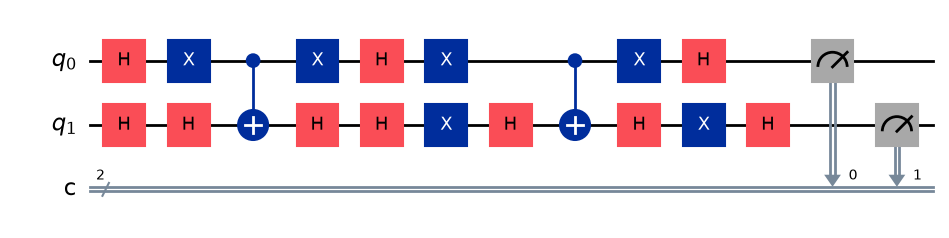

In [5]:
# Assemble the full Grover circuit
def build_grover(n, marked, iterations):
    qc = QuantumCircuit(n, n)
    qubits = list(range(n))
    qc.h(qubits)                       # equal superposition
    for _ in range(iterations):
        oracle(qc, qubits, marked)
        diffusion(qc, qubits)
    qc.measure(qubits, qubits)
    return qc

qc = build_grover(n, secret_key, iterations)
qc.draw("mpl")

Most likely key (binary): 10 = key 2


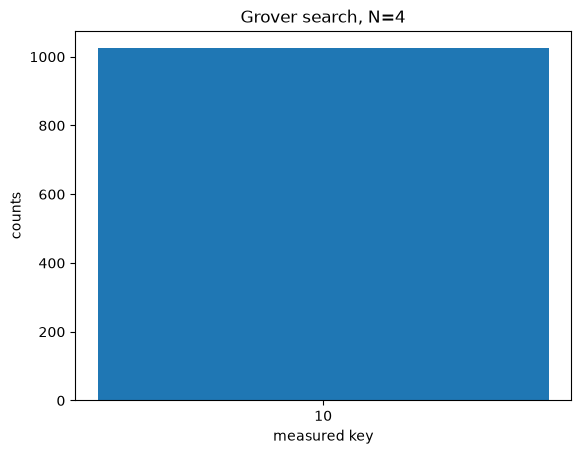

In [6]:
# Run on the simulator
tqc = transpile(qc, sim)
counts = sim.run(tqc, shots=1024).result().get_counts()

# The most frequent result should be the secret key
best = max(counts, key=counts.get)
print("Most likely key (binary):", best, "= key", int(best, 2))

plt.bar(counts.keys(), counts.values())
plt.title(f"Grover search, N={N}")
plt.xlabel("measured key"); plt.ylabel("counts"); plt.show()


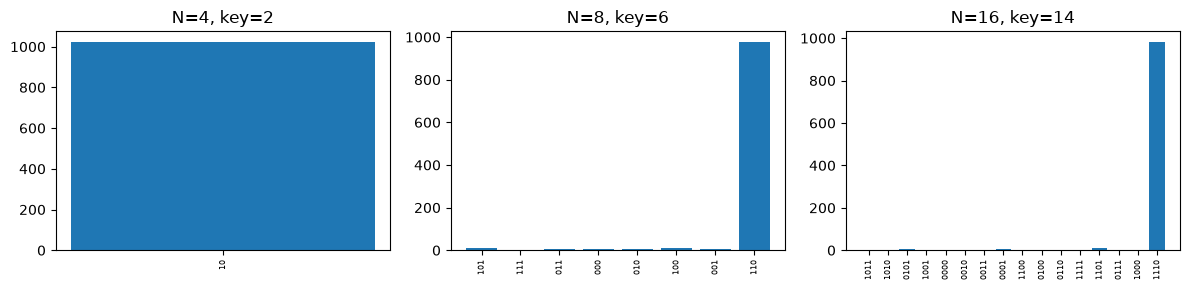

N= 4: 1 iteration(s), key 2 found as 2, measured success rate 100.0%
N= 8: 2 iteration(s), key 6 found as 6, measured success rate 95.5%
N=16: 3 iteration(s), key 14 found as 14, measured success rate 96.0%


In [7]:
# N = 4, 8 and 16: does the peak land on the secret key each time, and how sharp is it?
# (Aer is noise-free; a perfect run of Grover's search still isn't 100% for N = 8 and 16.)
results = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, N_i in zip(axes, (4, 8, 16)):
    n_i = int(np.log2(N_i))
    key_i = N_i - 2                                   # an arbitrary key to find
    its = int(np.floor((np.pi / 4) * np.sqrt(N_i)))
    qc_i = build_grover(n_i, key_i, its)
    c_i = sim.run(transpile(qc_i, sim), shots=1024).result().get_counts()
    top = max(c_i, key=c_i.get)
    results[N_i] = (key_i, its, int(top, 2), c_i.get(format(key_i, f"0{n_i}b"), 0) / 1024)
    ax.bar(c_i.keys(), c_i.values()); ax.set_title(f"N={N_i}, key={key_i}"); ax.tick_params(axis="x", labelrotation=90, labelsize=6)
    assert int(top, 2) == key_i, f"N={N_i}: search peaked on {int(top, 2)}, not {key_i}"
plt.tight_layout(); plt.show()
for N_i, (key_i, its, found, p) in results.items():
    print(f"N={N_i:2d}: {its} iteration(s), key {key_i} found as {found}, measured success rate {p:.1%}")


### Run it through qBraid

IonQ's simulator is free, and its `noise_model` option adds IonQ's gate noise, which sits mostly on two-qubit gates. Grover's circuit grows fast: N = 4 needs 2 two-qubit gates, N = 8 needs 24 and N = 16 needs 84, before routing. The cell below sends the N = 4 circuit. The N = 8 and N = 16 runs, the Quantinuum H2 emulator runs and the Rigetti Cepheus (real QPU) runs were sent separately; their job IDs and results are in `WRITEUP.md`, Step 2, Part 5.

In [8]:
# --- Run on a quantum computer through qBraid ---
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()   # in qBraid Lab this uses your account automatically

# 1) Practice for free: IonQ's simulator with an approximate noise model of IonQ Forte
device = provider.get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})

# 2) Real hardware (uses credits: 38.5 per 200-shot run on Rigetti Cepheus):
# device = provider.get_device("aws:rigetti:qpu:cepheus-1-108q")
# job = device.run(qc, shots=200)

# 3) Also free: Quantinuum's H2 emulator. It models a real trapped-ion computer's noise, readout
#    error included. Accept Quantinuum's terms once first (Devices > Quantinuum in your qBraid account).
#    It's an emulator: label its results that way, not as hardware.
# device = provider.get_device("quantinuum:quantinuum:sim:h2-emulator")
# job = device.run(qc, shots=200)

print("Job ID:", job.id)          # copy this into your write-up
hw_counts = job.result().data.get_counts()
print(hw_counts)

Job ID: ionq:ionq:sim:simulator-a7ae-qjob-6af7caaff15852ed27b7215d


{'10': 200}


## Results

- On the noise-free simulator the search peaks on the secret key for N = 4, 8 and 16: 100.0%, 95.5% and 96.0% success (exact theory 100%, 94.5% and 96.1%).
- IonQ's noisy simulator (forte-1 noise model, 200 shots): 100%, 71.5% and 36.0% for N = 4, 8 and 16. Rigetti Cepheus, a real QPU: 88.5%, 45.0% and 4.5%. The job IDs are in the write-up.
- `check_grover.py` checks this oracle and diffuser against the exact Grover formula for every key, N = 2 to 32.
- The written answer, and where symmetric keys sit in the migration plan, are in `WRITEUP.md`, Step 2, Part 5.